## 1. Imports and data loading

In [1]:
import csv
import os
import platform
import time
from pathlib import Path

import jiwer
import matplotlib.pyplot as plt
import soundfile as sf
from faster_whisper import WhisperModel

DATA = Path("data")
with open(DATA / "manifest.csv", newline="", encoding="utf-8") as f:
    manifest = list(csv.DictReader(f))

refs = [r["reference"] for r in manifest]
audios = [sf.read(DATA / r["file"], dtype="float32")[0] for r in manifest]
durations = [len(a) / 16000 for a in audios]

print(f"{len(audios)} files, {sum(durations):.0f} s of audio in total")
print("CPU:", platform.processor(), "| logical cores:", os.cpu_count())

34 files, 130 s of audio in total
CPU: AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | logical cores: 16


c:\Users\zubak\Desktop\voice-overlay\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. WER count

In [2]:
import re
from num2words import num2words   # python -m pip install num2words

base_normalize = jiwer.Compose([
    jiwer.ToLowerCase(),
    jiwer.RemovePunctuation(),
    jiwer.RemoveMultipleSpaces(),
    jiwer.Strip(),
])

SPECIAL = {"gonna": "going to", "gotta": "got to", "kinda": "kind of",
        "can't": "can not", "won't": "will not", "ok": "okay"}

def fix(s):
    s = s.lower().replace("’", "'")
    for k, v in SPECIAL.items():
        s = re.sub(rf"\b{re.escape(k)}\b", v, s)
    s = re.sub(r"n't\b", " not", s)
    s = re.sub(r"'re\b", " are", s)
    s = re.sub(r"'m\b", " am", s)
    s = re.sub(r"'ve\b", " have", s)
    s = re.sub(r"'ll\b", " will", s)
    s = re.sub(r"\b(how|that|it|what|here|there|who)'s\b", r"\1 is", s)
    s = s.replace("%", " percent")
    s = re.sub(r"\$(\d+)", r"\1 dollars", s)
    s = re.sub(r"\d+", lambda m: " " + num2words(int(m.group())) + " ", s)
    s = s.replace("-", " ")
    return base_normalize(s)

def wer(refs, hyps):
    return jiwer.wer([fix(r) for r in refs], [fix(h) for h in hyps])

def wer_raw(refs, hyps):
    return jiwer.wer([base_normalize(r) for r in refs],
                    [base_normalize(h) for h in hyps])

## 3. Single-shot function

In [3]:
def evaluate(model_name, compute_type, device="cpu", beam_size=5):
    t0 = time.perf_counter()
    model = WhisperModel(model_name, device=device, compute_type=compute_type)
    load_s = time.perf_counter() - t0

    segs, _ = model.transcribe(audios[0], language="en",
    beam_size=beam_size, vad_filter=True)
    list(segs)

    hyps, times = [], []
    for audio in audios:
        t = time.perf_counter()
        segs, _ = model.transcribe(
            audio, language="en", beam_size=beam_size,
            vad_filter=True, condition_on_previous_text=False,
        )
        text = " ".join(s.text.strip() for s in segs).strip()
        times.append(time.perf_counter() - t)
        hyps.append(text)

    row = {
        "model": model_name,
        "compute": compute_type,
        "device": device,
        "beam": beam_size,
        "WER_%": round(100 * wer(refs, hyps), 2),
        "RTF": round(sum(times) / sum(durations), 3),
        "avg_latency_s": round(sum(times) / len(times), 2),
        "load_s": round(load_s, 1),
    }
    return row, hyps

## 4. Activating all configurations

In [4]:
configs = [
    (m, c)
    for m in ["tiny.en", "base.en", "small.en"]
    for c in ["int8", "float32"]
]

results, all_hyps = [], {}
for m, c in configs:
    print("running:", m, c)
    row, hyps = evaluate(m, c)
    results.append(row)
    all_hyps[(m, c)] = hyps

cols = list(results[0].keys())
with open("results.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=cols)
    w.writeheader()
    w.writerows(results)

print(" | ".join(cols))
for r in results:
    print(" | ".join(str(r[c]) for c in cols))

running: tiny.en int8
running: tiny.en float32
running: base.en int8
running: base.en float32
running: small.en int8
running: small.en float32
model | compute | device | beam | WER_% | RTF | avg_latency_s | load_s
tiny.en | int8 | cpu | 5 | 34.72 | 0.064 | 0.25 | 0.6
tiny.en | float32 | cpu | 5 | 34.34 | 0.083 | 0.32 | 0.4
base.en | int8 | cpu | 5 | 29.06 | 0.117 | 0.45 | 0.5
base.en | float32 | cpu | 5 | 30.57 | 0.168 | 0.64 | 0.5
small.en | int8 | cpu | 5 | 13.21 | 0.326 | 1.25 | 1.1
small.en | float32 | cpu | 5 | 13.96 | 0.51 | 1.95 | 1.0


## 5.

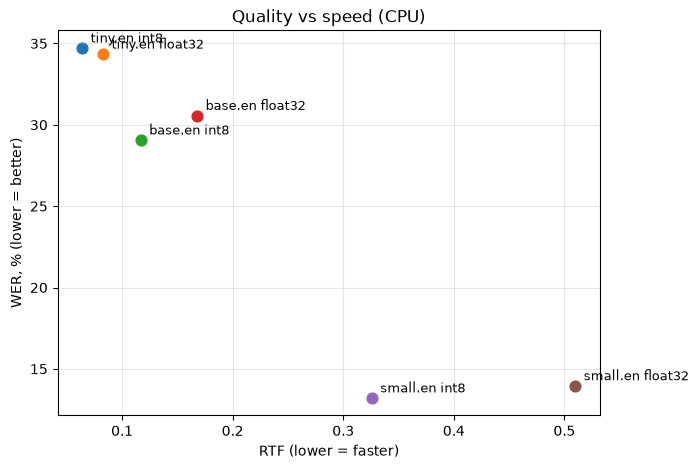

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for r in results:
    ax.scatter(r["RTF"], r["WER_%"], s=60)
    ax.annotate(f'{r["model"]} {r["compute"]}',
                (r["RTF"], r["WER_%"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)

ax.set_xlabel("RTF (lower = faster)")
ax.set_ylabel("WER, % (lower = better)")
ax.set_title("Quality vs speed (CPU)")
ax.grid(alpha=0.3)
fig.savefig("quality_vs_speed.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Mistakes analyzing

In [6]:
m, c = "small.en", "int8"
for ref, hyp in zip(refs, all_hyps[(m, c)]):
    if fix(ref) != fix(hyp):
        print("REF:", ref)
        print("HYP:", hyp)
        print()

REF: Oh, come on, you've gotta be kidding me!
HYP: Oh, come on, you gotta be kidding me.

REF: I'm a bit busy right now, call you back in ten?
HYP: I'm a bit busy right now, call you back in town

REF: No way, that's crazy! How did that happen?
HYP: No way, this is crazy. How did it happen?

REF: Check the SQL query and deploy the code.
HYP: Check the stql query and deploy the code

REF: The backend API returned an error.
HYP: The back end appeared in the ear.

REF: Did you push the hotfix to GitHub?
HYP: Did you push the hotfix to give up?

REF: Save the file to the PostgreSQL database.
HYP: Save the file to the Postgres SQL database.

REF: What's the weather in San Francisco today?
HYP: What's up as a result of what is good today?

REF: Remind me to call Sarah at three in the afternoon.
HYP: remind me to call sarah 3 in the afternoon

REF: Cancel my meeting with Alex.
HYP: Again, so maybe it's Alex

REF: Hold on while I transfer your call to John.
HYP: Hold on while I transfer your c